# Predicting Retrieval Failure in Consumer Health Question Answering
**Final Project** · Jeremy Childress · Programming for Health Data Science

**Why this matters for health.** Patient-facing chatbots and clinical assistants often answer questions by first searching a set of trusted documents. If the search pulls the wrong passage, the tool can still write a confident answer that is wrong, and the patient has no way to tell. This project asks whether we can predict, before any answer is written, that a search is likely to fail, so the question can be sent to a stronger method or to a person instead.

**Data.** MedQuAD, consumer health questions paired with answers from NIH websites such as cancer.gov, GARD, and MedlinePlus (Ben Abacha & Demner-Fushman, 2019). You can also upload your own question and answer dataset (Section 4).

**Target.** `failure` (1 = the correct answer is not in the top 10 search results, 0 = it is). The dataset does not include this variable. The notebook creates it by running four search methods on each question and checking the results against the known question and answer pairs.

**Primary metric.** ROC-AUC, chosen in the configuration cell and justified in Section 12.

### How to use this notebook
1. Choose **Runtime > Run all**. With the default settings it analyzes MedQuAD and needs no uploads.
2. To analyze your own data, set `DATA_SOURCE = 'upload'` in the configuration cell, then run all. A file picker appears in Section 4. Your file needs a `question` column and an `answer` column. The README lists the optional columns.

### Outline
1. Configuration · 2. Setup and imports · 3. Helper functions · 4. Data input, profiling, and validation · 5. Cleaning and preprocessing · 6. Descriptive statistics · 7. Search methods (creating the target) · 8. Feature engineering and adaptive pipeline decisions · 9. Exploratory visualizations · 10. Inferential statistics · 11. Supervised classification models · 12. Evaluation and best model selection · 13. Decision threshold · 14. Feature importance · 15. Interpretation · 16. Pipeline design summary

## 1. Configuration
Every setting the pipeline uses is in this one cell. Changing a value here changes the whole analysis, with no edits needed further down.

In [1]:
# =============================================================================
# CONFIGURATION  (edit this cell only)
# =============================================================================

# --- Data input -------------------------------------------------------------
# 'medquad' : the project dataset (loads automatically, no upload needed)
# 'upload'  : choose a file from your computer (Colab file picker)
# 'path'    : read a file from UPLOAD_PATH
DATA_SOURCE = 'medquad'
UPLOAD_PATH = None            # e.g. 'data/example_upload.csv' when DATA_SOURCE = 'path'

# --- Analysis goals ---------------------------------------------------------
PRIMARY_METRIC = 'roc_auc'    # how the best model is chosen: 'roc_auc', 'pr_auc', 'f1', 'recall', 'balanced_accuracy'
TARGET_RECALL  = 0.90         # share of failed searches the final model should catch (Section 13)
RUN_TUNING     = True         # grid search for logistic regression and random forest

# --- Search settings --------------------------------------------------------
SAMPLE_SIZE  = 2000           # questions to search (reduced automatically if the dataset is smaller)
TOP_K        = 10             # a search succeeds if the correct answer is in the top K results
LSA_DIMS     = 200            # dimensions for the LSA semantic search method

# --- Pipeline rules ---------------------------------------------------------
RANDOM_STATE        = 42      # used everywhere for reproducibility
N_FOLDS             = 5       # cross-validation folds
MIN_QTYPE_N         = 100     # question types with fewer questions are grouped into "other"
MIN_QUESTIONS       = 100     # smallest dataset the pipeline will accept
IMBALANCE_THRESHOLD = 0.45    # if the minority class share is below this, class weights are used
MAX_ROWS_FOR_SVM    = 20000   # SVM is skipped above this many training rows (it scales poorly)
ALPHA               = 0.05    # significance level for inferential tests

# --- File locations ---------------------------------------------------------
REPO_RAW     = 'https://raw.githubusercontent.com/f007yss/dataset-selection-lab/main/data/'
RAW_FILE     = 'medquad_raw.csv.gz'
RESULTS_FILE = 'retrieval_results.csv'
USE_CACHED_RETRIEVAL = False  # reuse saved MedQuAD search results instead of rerunning the searches

## 2. Setup and Imports
Packages that Colab does not include by default are installed only if they are missing.

In [2]:
import importlib, subprocess, sys

# Install any missing dependencies (Colab already has most of them)
for pkg in ['xgboost', 'statsmodels', 'seaborn']:
    if importlib.util.find_spec(pkg) is None:
        print('Installing', pkg)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=False)

import os, re, glob, io, warnings
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats
from IPython.display import display, Markdown

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier,
                              AdaBoostClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             balanced_accuracy_score, recall_score, precision_score, f1_score,
                             accuracy_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report)
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('xgboost could not be loaded, so the XGBoost model will be skipped')

warnings.filterwarnings('ignore')
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 80)

# Every adaptive choice the pipeline makes is recorded here and summarized in Section 8
decisions = []
def log_decision(step, choice, reason):
    decisions.append({'Step': step, 'Decision': choice, 'Reason': reason})
    print(f'[{step}] {choice}. {reason}')

print('Libraries loaded. Random seed =', RANDOM_STATE)

Libraries loaded. Random seed = 42


## 3. Helper Functions
Each step that is used more than once, or that could fail, is a separate function with a short docstring.

In [3]:
# =============================================================================
# INPUT VALIDATION FOR SETTINGS
# =============================================================================
METRICS = {   # config name -> (sklearn scorer, column in the comparison table)
    'roc_auc':           ('roc_auc',           'ROC-AUC'),
    'pr_auc':            ('average_precision', 'PR-AUC'),
    'f1':                ('f1',                'F1'),
    'recall':            ('recall',            'Recall'),
    'balanced_accuracy': ('balanced_accuracy', 'Bal. Accuracy'),
}

def check_settings():
    """Stop early with a clear message if a configuration value is not valid."""
    if DATA_SOURCE not in ('medquad', 'upload', 'path'):
        raise ValueError(f"DATA_SOURCE must be 'medquad', 'upload', or 'path', not {DATA_SOURCE!r}")
    if PRIMARY_METRIC not in METRICS:
        raise ValueError(f'PRIMARY_METRIC must be one of {list(METRICS)}, not {PRIMARY_METRIC!r}')
    if not 0 < TARGET_RECALL < 1:
        raise ValueError('TARGET_RECALL must be between 0 and 1')
    if TOP_K < 5:
        raise ValueError('TOP_K must be at least 5 (the score gap uses the 5th result)')
    if DATA_SOURCE == 'path' and not UPLOAD_PATH:
        raise ValueError("Set UPLOAD_PATH when DATA_SOURCE = 'path'")
    print('Settings are valid.')


# =============================================================================
# DATA LOADING
# =============================================================================
def parse_medquad_xml(folder):
    """Read the original MedQuAD XML files into a DataFrame."""
    rows = []
    for f in sorted(glob.glob(os.path.join(folder, '*_QA', '*.xml'))):
        doc = ET.parse(f).getroot()
        for qa in doc.iter('QAPair'):
            q, a = qa.find('Question'), qa.find('Answer')
            rows.append({'qid': q.get('qid'), 'source': doc.get('source'), 'doc_id': doc.get('id'),
                         'focus': (doc.findtext('Focus') or '').strip(), 'qtype': q.get('qtype'),
                         'question': (q.text or '').strip(),
                         'answer': (a.text or '').strip() if a is not None else ''})
    return pd.DataFrame(rows)


def load_medquad():
    """Load MedQuAD from the first location that works:
    local data/ folder, then this project's GitHub repo, then the original MedQuAD XML."""
    local = os.path.join('data', RAW_FILE)
    if os.path.exists(local):
        print('MedQuAD loaded from local file:', local)
        return pd.read_csv(local, dtype=str, keep_default_na=False)
    try:
        df = pd.read_csv(REPO_RAW + RAW_FILE, dtype=str, keep_default_na=False, compression='gzip')
        print('MedQuAD loaded from the project GitHub repo')
        return df
    except Exception as e:
        print(f'Repo copy not available ({type(e).__name__}), rebuilding from the original MedQuAD XML')
    if not os.path.exists('MedQuAD'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/abachaa/MedQuAD.git'], check=False)
    return parse_medquad_xml('MedQuAD')


def read_table(name, content=None):
    """Read a CSV, TSV, gzipped CSV, or Excel file from a path or from uploaded bytes."""
    src = io.BytesIO(content) if content is not None else name
    lower = name.lower()
    if lower.endswith(('.xlsx', '.xls')):
        return pd.read_excel(src, dtype=str).fillna('')
    sep = '\t' if lower.endswith(('.tsv', '.tsv.gz')) else ','
    comp = 'gzip' if lower.endswith('.gz') else None
    return pd.read_csv(src, dtype=str, keep_default_na=False, sep=sep, compression=comp)


def load_user_data():
    """Get the user's dataset from the Colab file picker or from UPLOAD_PATH."""
    if DATA_SOURCE == 'path':
        if not os.path.exists(UPLOAD_PATH):
            raise FileNotFoundError(f'No file found at {UPLOAD_PATH}')
        print('Reading', UPLOAD_PATH)
        return read_table(UPLOAD_PATH), os.path.basename(UPLOAD_PATH)
    try:
        from google.colab import files
    except ImportError:
        raise RuntimeError("The file picker only works in Google Colab. Outside Colab, use DATA_SOURCE = 'path'.")
    print('Choose a CSV, TSV, or Excel file with question and answer columns.')
    uploaded = files.upload()
    if not uploaded:
        raise ValueError('No file was uploaded')
    name, content = next(iter(uploaded.items()))
    return read_table(name, content), name


def standardize_columns(df):
    """Match column names to the pipeline's schema and fill optional columns that are missing."""
    df = df.copy()
    df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]
    aliases = {'query': 'question', 'q': 'question', 'response': 'answer', 'passage': 'answer',
               'question_type': 'qtype', 'type': 'qtype', 'document_id': 'doc_id', 'topic': 'focus'}
    df = df.rename(columns={k: v for k, v in aliases.items() if k in df.columns and v not in df.columns})
    missing = [c for c in ('question', 'answer') if c not in df.columns]
    if missing:
        raise ValueError(f'Required column(s) missing: {missing}. Found: {list(df.columns)}')
    provided = [c for c in ('qid', 'source', 'doc_id', 'focus', 'qtype') if c in df.columns]
    defaults = {'qid': df.index.astype(str), 'source': 'uploaded', 'doc_id': df.index.astype(str),
                'focus': '', 'qtype': 'unknown'}
    for col, val in defaults.items():
        if col not in df.columns:
            df[col] = val
    return df[['qid', 'source', 'doc_id', 'focus', 'qtype', 'question', 'answer']], provided


def profile_dataset(df):
    """Automated profile: type, missing values, unique values, and an example for every column."""
    blank = df.apply(lambda s: s.astype(str).str.strip().eq('').sum())
    prof = pd.DataFrame({
        'dtype':     df.dtypes.astype(str),
        'non-blank': len(df) - blank,
        'blank':     blank,
        'blank %':   (blank / len(df) * 100).round(1),
        'unique':    df.nunique(),
        'example':   [str(df[c].iloc[0])[:50] for c in df.columns],
    })
    print(f'Rows: {len(df):,}   Columns: {df.shape[1]}   Fully duplicated rows: {df.duplicated().sum():,}')
    display(prof)
    return prof


def validate_raw(df):
    """Check the standardized data before any analysis. Raises an error with a clear message if it fails."""
    if len(df) == 0:
        raise ValueError('The dataset is empty')
    answered = (df['question'].str.strip() != '') & (df['answer'].str.strip() != '')
    if answered.sum() < MIN_QUESTIONS:
        raise ValueError(f'Only {answered.sum()} rows have both a question and an answer. At least {MIN_QUESTIONS} are needed.')
    dup = df['qid'].duplicated().sum()
    if dup:
        print(f'Note: {dup:,} question IDs repeat (MedQuAD restarts IDs in each source), so a new unique ID (uid) is created.')
    print(f'Validation passed: {answered.sum():,} usable question and answer pairs.')


def validate_model_table(df, features, target, strict):
    """Check the modeling table. With the project dataset (strict), the course requirements are enforced."""
    problems = []
    if df[target].nunique() != 2:
        problems.append('the target has only one class, so there is nothing to predict')
    if len(df) < 300:
        problems.append('fewer than 300 observations')
    if df[features].isna().any().any():
        problems.append('missing values in predictors')
    if problems:
        raise ValueError('Modeling table failed validation: ' + '; '.join(problems))
    if len(features) < 10:
        msg = f'only {len(features)} predictors (the course requires at least 10)'
        if strict:
            raise ValueError('Modeling table failed validation: ' + msg)
        print('Warning:', msg, '- this is expected for uploaded data with fewer optional columns.')
    print(f'Modeling table passed validation: {len(df):,} rows, {len(features)} predictors, binary target.')


# =============================================================================
# SEARCH METHODS
# =============================================================================
TOKEN = r'(?u)\b[a-z0-9]+\b'

def build_bm25(passages, k1=1.5, b=0.75):
    """Vectorized BM25 (see the formula in Section 7). Returns (vectorizer, weighted document matrix, idf)."""
    cv = CountVectorizer(token_pattern=TOKEN, lowercase=True)
    tf = cv.fit_transform(passages).tocsr().astype(float)
    n, dl = tf.shape[0], np.asarray(tf.sum(axis=1)).ravel()
    df_ = np.bincount(tf.indices, minlength=tf.shape[1])          # documents containing each term
    idf = np.log((n - df_ + 0.5) / (df_ + 0.5) + 1)
    tf = tf.tocoo()
    denom = tf.data + k1 * (1 - b + b * dl[tf.row] / dl.mean())    # length normalization
    w = sparse.csr_matrix((idf[tf.col] * tf.data * (k1 + 1) / denom, (tf.row, tf.col)), shape=tf.shape)
    return cv, w, idf


def rrf(rank_lists, k=60):
    """Reciprocal rank fusion: combine several ranked lists into one score per passage."""
    scores = {}
    for ranks in rank_lists:
        for r, pid in enumerate(ranks):
            scores[pid] = scores.get(pid, 0) + 1 / (k + r + 1)
    return scores


# =============================================================================
# EVALUATION  (extends the course get_metrics_score function)
# =============================================================================
def fmt_p(p):
    """Format a p-value for reporting."""
    return '< 0.001' if p < 0.001 else f'= {p:.3f}'


def get_scores(model, X):
    """Predicted probability of failure, or a decision score if the model has no probabilities."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(model, X_train, X_test, y_train, y_test, name):
    """Train and test metrics for one fitted model. Failure (1) is the positive class."""
    row = {'Model': name}
    for split, X, y in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        s = get_scores(model, X)
        row[f'{split} ROC-AUC'] = roc_auc_score(y, s)
        row[f'{split} PR-AUC'] = average_precision_score(y, s)
    pred = model.predict(X_test)
    row['Test Recall']        = recall_score(y_test, pred)
    row['Test Precision']     = precision_score(y_test, pred, zero_division=0)
    row['Test F1']            = f1_score(y_test, pred)
    row['Test Bal. Accuracy'] = balanced_accuracy_score(y_test, pred)
    row['Test Accuracy']      = accuracy_score(y_test, pred)
    row['Test Brier']         = brier_score_loss(y_test, model.predict_proba(X_test)[:, 1]) if hasattr(model, 'predict_proba') else np.nan
    return row


def plot_confusion(y_true, y_pred, title):
    """Confusion matrix with counts and percentages."""
    cm = confusion_matrix(y_true, y_pred)
    labels = np.array([f'{c}\n{c / cm.sum():.1%}' for c in cm.flatten()]).reshape(2, 2)
    plt.figure(figsize=(6, 4.5))
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False,
                xticklabels=['Pred: success', 'Pred: failure'], yticklabels=['True: success', 'True: failure'])
    plt.title(title)
    plt.tight_layout()
    plt.show()
    print(classification_report(y_true, y_pred, target_names=['success', 'failure']))

print('Helper functions defined.')

Helper functions defined.


## 4. Data Input, Profiling, and Validation
With `DATA_SOURCE = 'medquad'` the project dataset loads automatically. It tries a local copy, then the copy in this project's GitHub repo, then rebuilds it from the original MedQuAD XML files. With `DATA_SOURCE = 'upload'` a file picker appears so you can choose a file from your computer.

The data is then standardized to the pipeline's columns, profiled automatically, and validated. If anything is wrong, the notebook stops with a message that says what to fix.

In [4]:
check_settings()

if DATA_SOURCE == 'medquad':
    raw, source_label = load_medquad(), 'MedQuAD (project dataset)'
else:
    try:
        raw, source_label = load_user_data()
    except Exception as e:
        raise RuntimeError(f'Upload failed: {e}') from e

raw, provided_optional = standardize_columns(raw)
raw['uid'] = np.arange(len(raw))   # MedQuAD question IDs restart in each source, so a new unique ID is used
HAS_QTYPE  = raw['qtype'].nunique() > 1
HAS_SOURCE = raw['source'].nunique() > 1
HAS_DOC    = raw['doc_id'].nunique() < len(raw)

print('\nAutomated data profile')
profile = profile_dataset(raw.drop(columns='uid'))
validate_raw(raw)
print(f'\nData loaded and validated successfully: {source_label}')
print('Optional columns available:', ', '.join(c for c, ok in [('question type', HAS_QTYPE), ('source', HAS_SOURCE), ('page/document ID', HAS_DOC)] if ok) or 'none')

Settings are valid.
MedQuAD loaded from local file: data/medquad_raw.csv.gz



Automated data profile
Rows: 46,882   Columns: 7   Fully duplicated rows: 0


,dtype,non-blank,blank,blank %,unique,example
qid,str,46882,0,0.0,30084,0000001-1
source,str,46882,0,0.0,11,ADAM
doc_id,str,46877,5,0.0,5404,0000001
focus,str,46868,14,0.0,10498,A guide to clinical trials for cancer
qtype,str,46882,0,0.0,39,information
question,str,46882,0,0.0,44186,What is (are) A guide to clinical trials for cance
answer,str,15848,31034,66.2,15259,


Note: 16,798 question IDs repeat (MedQuAD restarts IDs in each source), so a new unique ID (uid) is created.
Validation passed: 15,848 usable question and answer pairs.

Data loaded and validated successfully: MedQuAD (project dataset)
Optional columns available: question type, source, page/document ID


## 5. Cleaning and Preprocessing
- **Missing answers.** Rows without an answer cannot be searched for. In MedQuAD, three MedlinePlus subsets had their answers removed for copyright reasons.
- **Duplicate questions.** Question text that appears more than once with different answers has no single correct answer, so those rows are dropped.
- **Duplicate answers.** Identical answers are searched as one passage, so finding the duplicate is not counted as a miss.
- **Rare question types** are grouped into "other" so no category is too small to learn from.

In [5]:
data = raw.copy()
for col in ['question', 'answer', 'focus']:
    data[col] = data[col].str.strip()

cleaning_log = {'Rows loaded': len(data)}
data = data[(data['answer'] != '') & (data['question'] != '')]
cleaning_log['After dropping missing questions or answers'] = len(data)
data = data[~data['question'].duplicated(keep=False)]
cleaning_log['After dropping duplicate questions'] = len(data)
display(pd.Series(cleaning_log, name='rows').to_frame())

counts = data['qtype'].value_counts()
data['qtype_group'] = np.where(data['qtype'].map(counts) >= MIN_QTYPE_N, data['qtype'], 'other')

passages = data['answer'].drop_duplicates().reset_index(drop=True)
data['pid'] = data['answer'].map({t: i for i, t in enumerate(passages)})
passage_doc = data.drop_duplicates('pid').set_index('pid')['doc_id'].sort_index().values
print(f'Unique answer passages to search: {len(passages):,}')

,rows
Rows loaded,46882
After dropping missing questions or answers,15848
After dropping duplicate questions,13675


Unique answer passages to search: 13,169


## 6. Descriptive Statistics

In [6]:
data['q_words']     = data['question'].str.split().str.len()
data['a_words']     = data['answer'].str.split().str.len()
data['focus_words'] = data['focus'].str.split().str.len().fillna(0)

display(data[['q_words', 'a_words', 'focus_words']].describe().round(1))
for col in ['q_words', 'a_words']:
    print(f'{col}: skewness = {stats.skew(data[col]):.2f}')

,q_words,a_words,focus_words
count,13675.0,13675.0,13675.0
mean,8.4,186.5,3.0
std,2.3,228.5,1.6
min,3.0,1.0,0.0
25%,7.0,67.0,2.0
50%,8.0,131.0,3.0
75%,10.0,246.0,4.0
max,27.0,3708.0,17.0


q_words: skewness = 0.72
a_words: skewness = 6.24


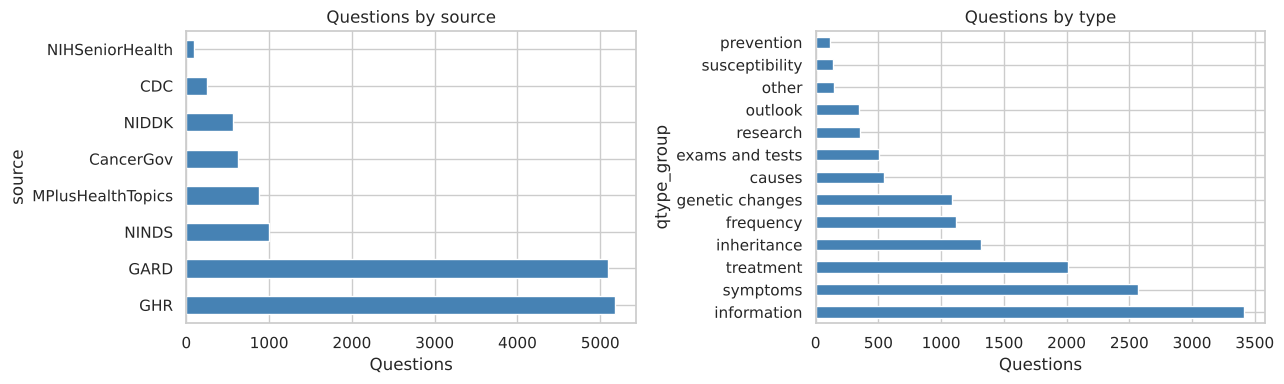

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
data['source'].value_counts().plot.barh(ax=axes[0], color='steelblue')
axes[0].set(title='Questions by source', xlabel='Questions')
data['qtype_group'].value_counts().plot.barh(ax=axes[1], color='steelblue')
axes[1].set(title='Questions by type', xlabel='Questions')
plt.tight_layout()
plt.show()

## 7. Search Methods (Creating the Target)
Four search methods are run on the same sample of questions.

| Method | How it works |
|---|---|
| **BM25** | Keyword matching that weights rare words more heavily and adjusts for passage length |
| **TF-IDF** | Keyword matching using cosine similarity of TF-IDF vectors |
| **LSA** | Semantic search. TF-IDF vectors are compressed to 200 dimensions so related words land near each other |
| **Hybrid** | Combines the BM25 and LSA rankings with reciprocal rank fusion |

### The BM25 formula
BM25 gives each passage $d$ a score for a question $q$:

$$
\text{BM25}(q, d) = \sum_{t \in q} \text{IDF}(t) \cdot \frac{f(t, d)\,(k_1 + 1)}{f(t, d) + k_1\left(1 - b + b\,\dfrac{|d|}{\text{avgdl}}\right)}
\qquad
\text{IDF}(t) = \ln\!\left(\frac{N - n_t + 0.5}{n_t + 0.5} + 1\right)
$$

- $f(t, d)$ is how many times word $t$ appears in passage $d$, and $|d|$ is the passage length.
- $\text{avgdl}$ is the average passage length, and $N$ is the number of passages.
- $n_t$ is the number of passages that contain $t$, so rare words get a high $\text{IDF}(t)$.
- $k_1 = 1.5$ limits how much repeating a word helps, and $b = 0.75$ controls the penalty for long passages.

**How it connects to the analysis.** The formula decides which passages reach the top 10, so it directly creates the target for the BM25 rows. It also produces three predictors. `mean_idf` and `max_idf` are the average and largest $\text{IDF}(t)$ of the question's words, and `top_score` and `score_gap` are the BM25 scores of the first and fifth results. A question made of common words has low IDF values, so many passages score about the same and the right one is easier to miss.

For each question and method, the search is a **success** if the question's own answer is in the top 10 results, and a **failure** otherwise.

In [8]:
def run_all_searches(data, passages, sample_size, top_k):
    """Run the four search methods on a sample of questions. Returns one row per question and method."""
    sample = data.sample(sample_size, random_state=RANDOM_STATE).reset_index(drop=True)
    questions = sample['question'].tolist()

    # BM25
    cv, bm25_w, idf = build_bm25(passages)
    q_bin = (cv.transform(questions) > 0).astype(float)
    bm25_scores = (q_bin @ bm25_w.T).toarray()

    # TF-IDF cosine similarity
    tfidf = TfidfVectorizer(token_pattern=TOKEN, sublinear_tf=True, stop_words='english')
    P = tfidf.fit_transform(passages)
    tfidf_scores = (tfidf.transform(questions) @ P.T).toarray()

    # LSA (semantic); dimensions cannot exceed the vocabulary size
    dims = min(LSA_DIMS, P.shape[1] - 1, len(passages) - 1)
    svd = TruncatedSVD(dims, random_state=RANDOM_STATE)
    P_lsa = normalize(svd.fit_transform(P))
    lsa_scores = normalize(svd.transform(tfidf.transform(questions))) @ P_lsa.T

    # Question-level features that do not depend on the method (IDF from the BM25 formula)
    vocab = cv.vocabulary_
    q_idf = [[idf[vocab[w]] for w in re.findall(TOKEN, q.lower()) if w in vocab] for q in questions]
    sample['mean_idf'] = [np.mean(v) if v else 0 for v in q_idf]
    sample['max_idf']  = [np.max(v) if v else 0 for v in q_idf]

    depth = min(100, len(passages))
    rows = []
    for i, row in sample.iterrows():
        ranked = {
            'BM25':   np.argsort(-bm25_scores[i])[:depth],
            'TF-IDF': np.argsort(-tfidf_scores[i])[:depth],
            'LSA':    np.argsort(-lsa_scores[i])[:depth],
        }
        fused = rrf([ranked['BM25'], ranked['LSA']])
        ranked['Hybrid'] = np.array(sorted(fused, key=fused.get, reverse=True)[:depth])
        raw_scores = {'BM25': bm25_scores[i], 'TF-IDF': tfidf_scores[i], 'LSA': lsa_scores[i]}

        for method, order in ranked.items():
            top = order[:top_k]
            s = np.array([fused[p] for p in top]) if method == 'Hybrid' else raw_scores[method][top]
            rows.append({
                'uid': row['uid'], 'method': method,
                'success': int(row['pid'] in top),
                'top_score': s[0], 'score_gap': s[0] - s[4],
                'same_page_top10': int((passage_doc[top] == passage_doc[top[0]]).sum()),
            })
    keep = ['uid', 'source', 'qtype', 'qtype_group', 'question', 'focus', 'q_words', 'focus_words', 'mean_idf', 'max_idf']
    return pd.DataFrame(rows).merge(sample[keep], on='uid')


# Conditional logic: sample size adapts to the dataset
n_search = min(SAMPLE_SIZE, len(data))
if n_search < SAMPLE_SIZE:
    log_decision('Sampling', f'search {n_search:,} questions instead of {SAMPLE_SIZE:,}', 'the dataset has fewer usable questions than SAMPLE_SIZE')
else:
    log_decision('Sampling', f'search a random sample of {n_search:,} questions', f'{len(data):,} questions are available')

cache = os.path.join('data', RESULTS_FILE)
results = None
if USE_CACHED_RETRIEVAL and DATA_SOURCE == 'medquad':
    for location in [cache, REPO_RAW + RESULTS_FILE]:
        try:
            results = pd.read_csv(location)
            log_decision('Searching', 'reuse saved search results', f'USE_CACHED_RETRIEVAL is on ({location})')
            break
        except Exception:
            continue
if results is None:
    results = run_all_searches(data, passages, n_search, TOP_K)
    if DATA_SOURCE == 'medquad':
        os.makedirs('data', exist_ok=True)
        results.to_csv(cache, index=False)
    print('Searches complete')

print(results.shape)
results.groupby('method')['success'].mean().round(3).sort_values().to_frame('success rate')

[Sampling] search a random sample of 2,000 questions. 13,675 questions are available


Searches complete
(8000, 15)


,success rate
method,
LSA,0.283
Hybrid,0.505
TF-IDF,0.801
BM25,0.838


## 8. Feature Engineering and Adaptive Pipeline Decisions
Raw search scores are on different scales for each method (BM25 scores run into the 30s, cosine scores are between 0 and 1), so the top score and score gap are standardized **within each method**. A flag marks template questions that start with "What is (are)". The modeling target is `failure = 1 - success`, so failed searches are the positive class.

The pipeline then adapts to the dataset. Predictors that do not vary are removed, categorical variables that are missing are skipped, and class weighting is switched on only if the target is imbalanced. Every decision is logged and shown in the table at the end of this section.

In [9]:
df = results.copy()
df['failure'] = 1 - df['success']
for col in ['top_score', 'score_gap']:
    df[col + '_z'] = df.groupby('method')[col].transform(lambda s: (s - s.mean()) / s.std()).fillna(0)
df['template_question'] = df['question'].str.lower().str.startswith('what is (are)').astype(int)

TARGET = 'failure'
NUMERIC = ['q_words', 'focus_words', 'mean_idf', 'max_idf', 'top_score_z', 'score_gap_z',
           'same_page_top10', 'template_question']
CATEGORICAL = ['method']

# Conditional logic: include categorical predictors only when the data has them
if HAS_QTYPE:
    CATEGORICAL.append('qtype_group')
else:
    log_decision('Features', 'skip question type', 'the dataset has no question type column')
if HAS_SOURCE:
    CATEGORICAL.append('source')
else:
    log_decision('Features', 'skip source', 'the dataset has a single source')

# Conditional logic: drop predictors with no variation (they carry no information)
constant = [c for c in NUMERIC if df[c].nunique() <= 1]
if constant:
    NUMERIC = [c for c in NUMERIC if c not in constant]
    log_decision('Features', f'drop {constant}', 'these predictors have the same value in every row')

FEATURES = NUMERIC + CATEGORICAL
validate_model_table(df, FEATURES, TARGET, strict=(DATA_SOURCE == 'medquad'))

# Conditional logic: class weighting depends on how imbalanced the target is
minority_share = df[TARGET].value_counts(normalize=True).min()
USE_CLASS_WEIGHTS = minority_share < IMBALANCE_THRESHOLD
CW = 'balanced' if USE_CLASS_WEIGHTS else None
log_decision('Imbalance', 'use balanced class weights' if USE_CLASS_WEIGHTS else 'no class weights',
             f'the minority class is {minority_share:.1%} of rows (threshold {IMBALANCE_THRESHOLD:.0%})')

print('\nClass balance (failure = 1):')
print(df[TARGET].value_counts(normalize=True).round(3))
display(df.groupby(TARGET)[NUMERIC].mean().round(2).T.rename(columns={0: 'success', 1: 'failure'}))

Modeling table passed validation: 8,000 rows, 11 predictors, binary target.
[Imbalance] use balanced class weights. the minority class is 39.3% of rows (threshold 45%)

Class balance (failure = 1):
failure
0    0.607
1    0.393
Name: proportion, dtype: float64


failure,success,failure
q_words,8.28,8.75
focus_words,3.00,3.08
mean_idf,2.53,2.54
max_idf,6.77,6.87
top_score_z,0.08,-0.12
score_gap_z,0.05,-0.08
same_page_top10,3.05,1.75
template_question,0.29,0.12


## 9. Exploratory Visualizations

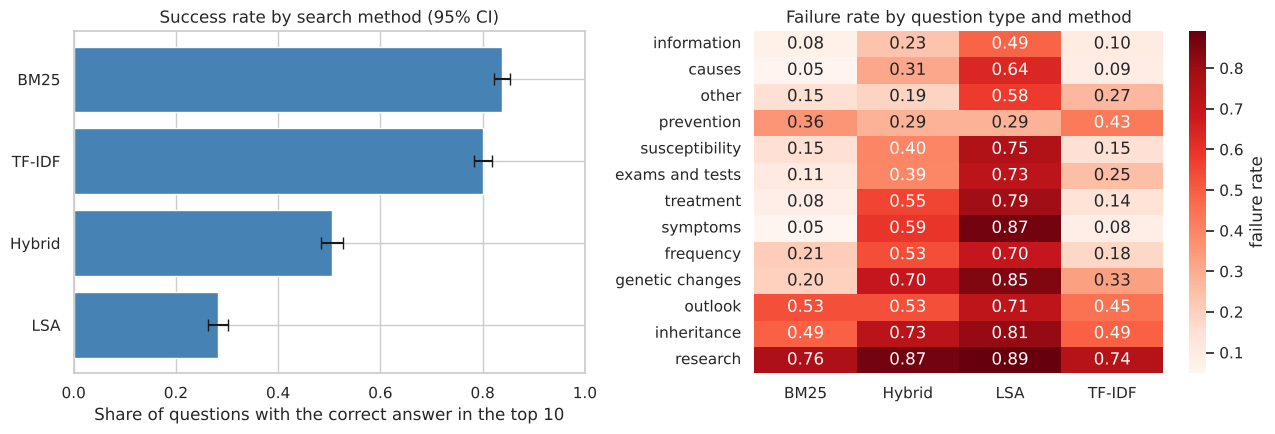

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

rate = df.groupby('method')['success'].mean().sort_values()
n = df.groupby('method').size()[rate.index]
err = 1.96 * np.sqrt(rate * (1 - rate) / n)
axes[0].barh(rate.index, rate.values, xerr=err.values, color='steelblue', capsize=4)
axes[0].set_xlim(0, 1)
axes[0].set(title='Success rate by search method (95% CI)', xlabel=f'Share of questions with the correct answer in the top {TOP_K}')

if HAS_QTYPE:
    heat = df.pivot_table(index='qtype_group', columns='method', values='failure', aggfunc='mean')
    heat = heat.loc[heat.mean(axis=1).sort_values().index]
    sns.heatmap(heat, annot=True, fmt='.2f', cmap='Reds', ax=axes[1], cbar_kws={'label': 'failure rate'})
    axes[1].set(title='Failure rate by question type and method', xlabel='', ylabel='')
else:
    sns.histplot(data=df, x='q_words', hue='failure', multiple='dodge', ax=axes[1], discrete=True)
    axes[1].set(title='Question length by outcome', xlabel='Words in question')
plt.tight_layout()
plt.show()

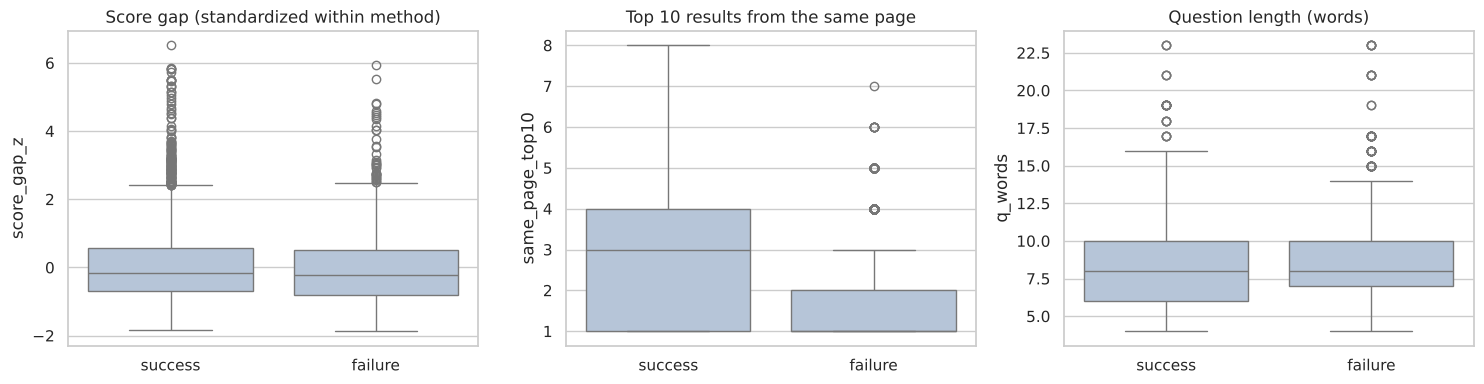

In [11]:
box_cols = [c for c in ['score_gap_z', 'same_page_top10', 'q_words'] if c in NUMERIC]
fig, axes = plt.subplots(1, len(box_cols), figsize=(5 * len(box_cols), 4))
axes = np.atleast_1d(axes)
titles = {'score_gap_z': 'Score gap (standardized within method)',
          'same_page_top10': 'Top 10 results from the same page', 'q_words': 'Question length (words)'}
for ax, col in zip(axes, box_cols):
    sns.boxplot(data=df, x='failure', y=col, ax=ax, color='lightsteelblue')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['success', 'failure'])
    ax.set(xlabel='', title=titles[col])
plt.tight_layout()
plt.show()

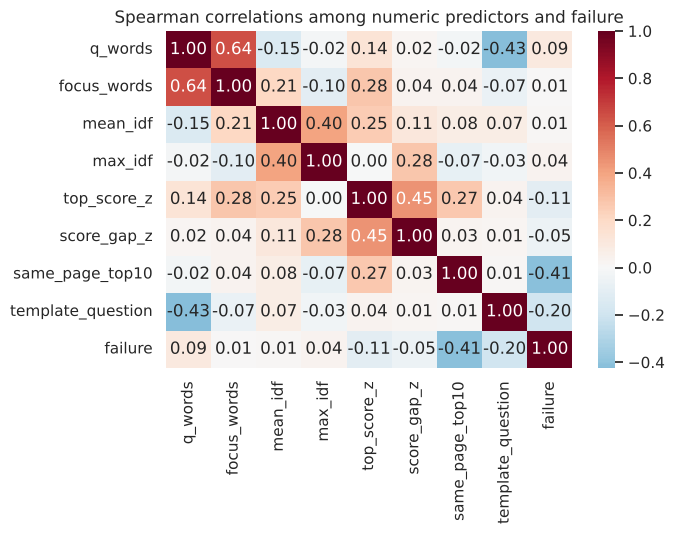

In [12]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[NUMERIC + [TARGET]].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Spearman correlations among numeric predictors and failure')
plt.tight_layout()
plt.show()

## 10. Inferential Statistics
Three questions, each matched to a test from the course materials, with $\alpha = 0.05$.

**1. Do the search methods fail at different rates on the same questions?** Every question is searched by every method, so the outcomes are paired. Cochran's Q test handles paired yes or no outcomes across more than two groups:

$$
Q = (k - 1)\,\frac{k \sum_{j=1}^{k} C_j^{2} - T^{2}}{k\,T - \sum_{i=1}^{n} R_i^{2}}
$$

where $k$ is the number of methods, $C_j$ is the number of failures for method $j$, $R_i$ is the number of methods that failed on question $i$, and $T$ is the total number of failures. If all methods fail equally often, $Q$ follows a chi-square distribution with $k - 1$ degrees of freedom. Pairwise follow-ups use McNemar's test with a Bonferroni correction.

**2. Is failure related to question type?** Chi-square test of independence, with Cramér's V as the effect size. Skipped automatically if the data has no question types.

**3. Do failed searches have smaller score gaps?** The pipeline checks normality first. If the score gap looks normal it uses Welch's t-test, and otherwise the Mann-Whitney U test.

In [13]:
# 1. Cochran's Q across all search methods (paired by question)
wide = df.pivot(index='uid', columns='method', values='failure')
q = cochrans_q(wide.values)
cochran_p = q.pvalue
print(f"Cochran's Q = {q.statistic:.1f}, df = {wide.shape[1] - 1}, p {fmt_p(cochran_p)}")

methods = list(wide.columns)
pairs = [(a, b) for i, a in enumerate(methods) for b in methods[i + 1:]]
rows = []
for a, b in pairs:
    table = pd.crosstab(wide[a], wide[b]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    p_adj = min(mcnemar(table.values, exact=False, correction=True).pvalue * len(pairs), 1)
    rows.append({'Comparison': f'{a} vs {b}', 'Failure rates': f'{wide[a].mean():.3f} vs {wide[b].mean():.3f}',
                 'p (Bonferroni)': fmt_p(p_adj).replace('= ', ''), 'Significant': p_adj < ALPHA})
mc = pd.DataFrame(rows)
display(mc)

Cochran's Q = 2301.7, df = 3, p < 0.001


,Comparison,Failure rates,p (Bonferroni),Significant
0,BM25 vs Hybrid,0.163 vs 0.495,< 0.001,True
1,BM25 vs LSA,0.163 vs 0.717,< 0.001,True
2,BM25 vs TF-IDF,0.163 vs 0.199,< 0.001,True
3,Hybrid vs LSA,0.495 vs 0.717,< 0.001,True
4,Hybrid vs TF-IDF,0.495 vs 0.199,< 0.001,True
5,LSA vs TF-IDF,0.717 vs 0.199,< 0.001,True


In [14]:
# 2. Chi-square: question type vs failure (conditional on the data having question types)
chi_p = cramers_v = None
if HAS_QTYPE:
    ct = pd.crosstab(df['qtype_group'], df['failure'])
    chi2, chi_p, dof, expected = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"Chi-square = {chi2:.1f}, df = {dof}, p {fmt_p(chi_p)}, Cramer's V = {cramers_v:.2f}")
    if expected.min() < 5:
        print(f'Warning: smallest expected count is {expected.min():.1f}, below 5, so the p-value is approximate')
    else:
        print(f'Smallest expected cell count: {expected.min():.1f} (at least 5, so the test is valid)')
else:
    log_decision('Inference', 'skip chi-square test', 'the dataset has no question types')

# 3. Score gap: choose the test from a normality check
gap_fail = df.loc[df['failure'] == 1, 'score_gap_z']
gap_succ = df.loc[df['failure'] == 0, 'score_gap_z']
normal_p = stats.shapiro(gap_succ.sample(min(500, len(gap_succ)), random_state=RANDOM_STATE)).pvalue
if normal_p >= ALPHA:
    gap_test = "Welch's t-test"
    stat, gap_p = stats.ttest_ind(gap_fail, gap_succ, equal_var=False, alternative='less')
    gap_effect = (gap_fail.mean() - gap_succ.mean()) / np.sqrt((gap_fail.var() + gap_succ.var()) / 2)
    effect_name = "Cohen's d"
else:
    gap_test = 'Mann-Whitney U test'
    stat, gap_p = stats.mannwhitneyu(gap_fail, gap_succ, alternative='less')
    gap_effect = 1 - 2 * stat / (len(gap_fail) * len(gap_succ))
    effect_name = 'rank-biserial r'
log_decision('Inference', f'use the {gap_test} for the score gap', f'Shapiro-Wilk normality p {fmt_p(normal_p)}')
print(f'{gap_test}: statistic = {stat:,.1f}, p {fmt_p(gap_p)}, {effect_name} = {gap_effect:.2f}')
print(f'Median score gap: failure = {gap_fail.median():.2f}, success = {gap_succ.median():.2f}')

Chi-square = 632.9, df = 12, p < 0.001, Cramer's V = 0.28
Smallest expected cell count: 22.0 (at least 5, so the test is valid)
[Inference] use the Mann-Whitney U test for the score gap. Shapiro-Wilk normality p < 0.001
Mann-Whitney U test: statistic = 7,147,335.0, p < 0.001, rank-biserial r = 0.06
Median score gap: failure = -0.22, success = -0.16


## 11. Supervised Classification Models

**Splitting.** Each question appears once per search method. If the same question landed in both training and test data, the model could memorize it and look better than it is. `StratifiedGroupKFold` keeps all rows for a question together and keeps the failure rate similar in every fold. One fold (about 20%) is held out as the test set, and the other folds are used for training and cross-validation.

**Models.** All supervised classification models from the course are included.
- Module 3: logistic regression, decision tree, support vector machine
- Module 4: random forest, bagging, AdaBoost, gradient boosting, XGBoost, stacking, and a neural network (MLP)

**Preprocessing.** Numeric predictors are standardized and categorical predictors are one-hot encoded, inside each model's pipeline so nothing from the test set leaks into training. Class weights follow the decision made in Section 8.

In [15]:
X, y, groups = df[FEATURES], df[TARGET], df['uid']
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

assert set(g_train).isdisjoint(set(groups.iloc[test_idx])), 'A question appears in both train and test'
print(f'Train: {len(X_train):,} rows ({g_train.nunique():,} questions), failure rate {y_train.mean():.3f}')
print(f'Test:  {len(X_test):,} rows ({groups.iloc[test_idx].nunique():,} questions), failure rate {y_test.mean():.3f}')

preprocess = ColumnTransformer([
    ('num', StandardScaler(), NUMERIC),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
])
cv_inner = StratifiedGroupKFold(n_splits=N_FOLDS - 1, shuffle=True, random_state=RANDOM_STATE)
pos_weight = (y_train == 0).sum() / (y_train == 1).sum() if USE_CLASS_WEIGHTS else 1.0

def make_pipe(clf):
    """Wrap a classifier with the shared preprocessing steps."""
    return Pipeline([('prep', preprocess), ('clf', clf)])

Train: 6,400 rows (1,600 questions), failure rate 0.393
Test:  1,600 rows (400 questions), failure rate 0.394


In [16]:
models = {
    # Module 3
    'Logistic Regression': make_pipe(LogisticRegression(class_weight=CW, max_iter=2000, random_state=RANDOM_STATE)),
    'Decision Tree':       make_pipe(DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight=CW, random_state=RANDOM_STATE)),
    'SVM (RBF)':           make_pipe(SVC(kernel='rbf', probability=True, class_weight=CW, random_state=RANDOM_STATE)),
    # Module 4
    'Random Forest':       make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=CW, n_jobs=-1, random_state=RANDOM_STATE)),
    'Bagging':             make_pipe(BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=5, class_weight=CW),
                                                       n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
    'AdaBoost':            make_pipe(AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE)),
    'Gradient Boosting':   make_pipe(GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE)),
    'Neural Network (MLP)': make_pipe(MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=500, random_state=RANDOM_STATE)),
    'Stacking':            make_pipe(StackingClassifier(
                               estimators=[('lr', LogisticRegression(class_weight=CW, max_iter=2000)),
                                           ('rf', RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight=CW, n_jobs=-1, random_state=RANDOM_STATE)),
                                           ('gb', GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE))],
                               final_estimator=LogisticRegression(max_iter=1000), cv=3, n_jobs=-1)),
}
if HAS_XGB:
    models['XGBoost'] = make_pipe(XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                                colsample_bytree=0.8, scale_pos_weight=pos_weight,
                                                eval_metric='logloss', random_state=RANDOM_STATE))

# Conditional logic: SVM training time grows quickly with the number of rows
if len(X_train) > MAX_ROWS_FOR_SVM:
    models.pop('SVM (RBF)')
    log_decision('Models', 'skip SVM', f'{len(X_train):,} training rows is above MAX_ROWS_FOR_SVM')

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print('Trained:', name)

Trained: Logistic Regression
Trained: Decision Tree


Trained: SVM (RBF)


Trained: Random Forest


Trained: Bagging


Trained: AdaBoost


Trained: Gradient Boosting


Trained: Neural Network (MLP)


Trained: Stacking


Trained: XGBoost


### Hyperparameter tuning
The two most interpretable models are tuned with a small grid search, using grouped cross-validation on the training set and the primary metric as the score.

In [17]:
scorer, metric_col = METRICS[PRIMARY_METRIC]
if RUN_TUNING:
    grids = {
        'Logistic Regression (Tuned)': (models['Logistic Regression'], {'clf__C': [0.01, 0.1, 1, 10]}),
        'Random Forest (Tuned)':       (models['Random Forest'], {'clf__max_depth': [6, 12, None], 'clf__min_samples_leaf': [5, 20]}),
    }
    for name, (pipe, grid) in grids.items():
        gs = GridSearchCV(pipe, grid, scoring=scorer, cv=cv_inner, n_jobs=-1)
        gs.fit(X_train, y_train, groups=g_train)
        models[name] = gs.best_estimator_
        print(f'{name}: best settings {gs.best_params_}, CV {metric_col} {gs.best_score_:.3f}')
else:
    log_decision('Models', 'skip tuning', 'RUN_TUNING is off')

Logistic Regression (Tuned): best settings {'clf__C': 1}, CV ROC-AUC 0.859


Random Forest (Tuned): best settings {'clf__max_depth': None, 'clf__min_samples_leaf': 5}, CV ROC-AUC 0.906


## 12. Evaluation and Best Model Selection

### Primary metric: ROC-AUC
The primary metric is set before any model is trained (`PRIMARY_METRIC` in the configuration cell). The default is ROC-AUC, which equals the probability that the model gives a randomly chosen failed search a higher risk score than a randomly chosen successful one:

$$
\text{AUC} = P\big(\hat{s}(x_{\text{failure}}) > \hat{s}(x_{\text{success}})\big)
$$

**Why this metric.** A real system would use the model to rank questions by risk and send the riskiest ones to a stronger method or a person. ROC-AUC measures exactly that ranking, and it does not depend on any one cutoff. Accuracy would be misleading because most searches succeed. The cutoff itself is chosen separately in Section 13, based on how many failures we need to catch.

**How the best model is chosen.** Models are ranked by their **cross-validated** primary metric on the training data, not by the test set, so the test set stays an honest check of the chosen model. The table also reports the course metrics (accuracy, recall, precision, F1) plus PR-AUC, balanced accuracy, and the Brier score (lower is better calibrated).

In [18]:
cv_scores = {}
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, groups=g_train, cv=cv_inner, scoring=scorer, n_jobs=-1)
    cv_scores[name] = (s.mean(), s.std())

comparison = pd.DataFrame([evaluate(m, X_train, X_test, y_train, y_test, n) for n, m in models.items()])
comparison[f'CV {metric_col}'] = comparison['Model'].map(lambda n: cv_scores[n][0])
comparison['CV SD'] = comparison['Model'].map(lambda n: cv_scores[n][1])
comparison = comparison.sort_values(f'CV {metric_col}', ascending=False).reset_index(drop=True)

cols = ['Model', f'CV {metric_col}', 'CV SD', 'Test ROC-AUC', 'Test PR-AUC', 'Test Accuracy', 'Test Recall',
        'Test Precision', 'Test F1', 'Test Bal. Accuracy', 'Test Brier', 'Train ROC-AUC']
display(comparison[cols].style.format({c: '{:.3f}' for c in cols if c != 'Model'}, na_rep='')
        .highlight_max(subset=[f'CV {metric_col}'], color='#d4edda'))

best_name = comparison.loc[0, 'Model']
best = models[best_name]
runner_up = comparison.loc[1]
print(f'\nBest model by cross-validated {metric_col}: {best_name} '
      f'({comparison.loc[0, f"CV {metric_col}"]:.3f}, next best {runner_up["Model"]} {runner_up[f"CV {metric_col}"]:.3f})')
print(f'Baseline PR-AUC (always guessing the failure rate): {y_test.mean():.3f}')

,Model,CV ROC-AUC,CV SD,Test ROC-AUC,Test PR-AUC,Test Accuracy,Test Recall,Test Precision,Test F1,Test Bal. Accuracy,Test Brier,Train ROC-AUC
0,Stacking,0.906,0.005,0.915,0.855,0.840,0.789,0.802,0.795,0.831,0.115,0.965
1,Random Forest,0.906,0.005,0.914,0.855,0.838,0.837,0.770,0.802,0.837,0.119,0.965
2,Random Forest (Tuned),0.906,0.005,0.914,0.855,0.838,0.837,0.770,0.802,0.837,0.119,0.965
3,Bagging,0.899,0.006,0.914,0.859,0.833,0.822,0.769,0.794,0.831,0.116,0.983
4,XGBoost,0.899,0.006,0.904,0.836,0.824,0.816,0.757,0.785,0.823,0.123,0.952
5,Neural Network (MLP),0.896,0.008,0.898,0.822,0.830,0.757,0.800,0.778,0.817,0.126,0.940
6,SVM (RBF),0.893,0.006,0.902,0.824,0.825,0.838,0.748,0.790,0.827,0.122,0.931
7,Gradient Boosting,0.890,0.005,0.896,0.822,0.819,0.717,0.801,0.757,0.801,0.128,0.920
8,Logistic Regression (Tuned),0.859,0.007,0.866,0.782,0.802,0.797,0.728,0.761,0.802,0.146,0.866
9,Logistic Regression,0.859,0.007,0.866,0.782,0.802,0.797,0.728,0.761,0.802,0.146,0.866



Best model by cross-validated ROC-AUC: Stacking (0.906, next best Random Forest 0.906)
Baseline PR-AUC (always guessing the failure rate): 0.394


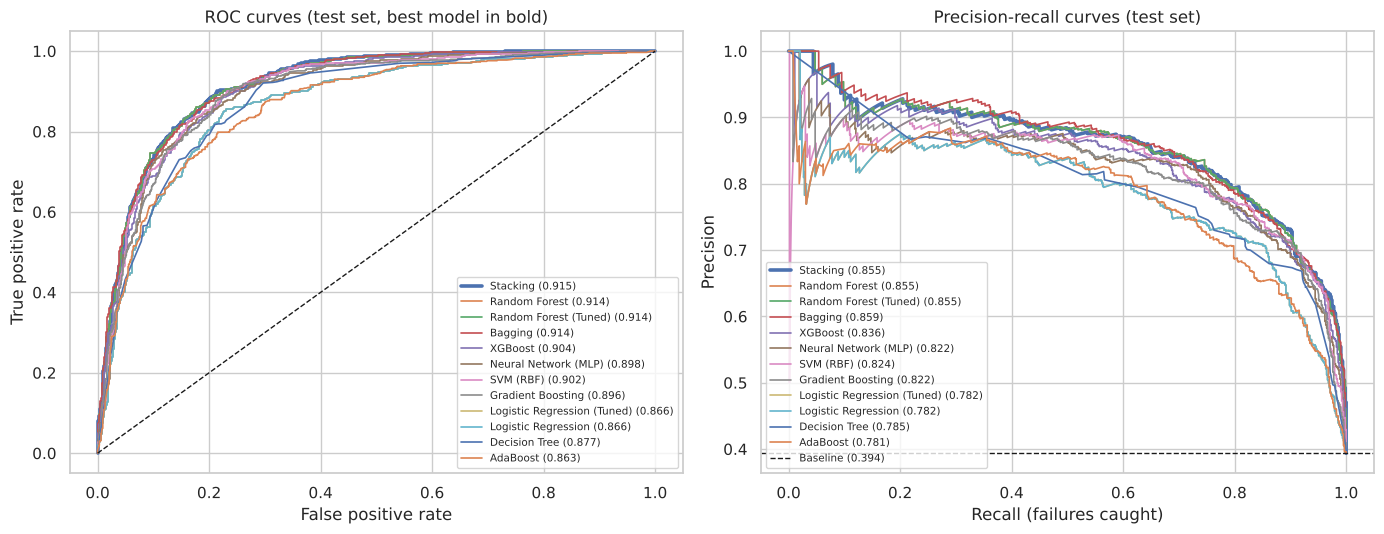

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name in comparison['Model']:
    s = get_scores(models[name], X_test)
    lw = 2.6 if name == best_name else 1.2
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[0].plot(fpr, tpr, lw=lw, label=f'{name} ({roc_auc_score(y_test, s):.3f})')
    axes[1].plot(rec, prec, lw=lw, label=f'{name} ({average_precision_score(y_test, s):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set(title='ROC curves (test set, best model in bold)', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'Baseline ({y_test.mean():.3f})')
axes[1].set(title='Precision-recall curves (test set)', xlabel='Recall (failures caught)', ylabel='Precision')
axes[0].legend(fontsize=7.5, loc='lower right')
axes[1].legend(fontsize=7.5, loc='lower left')
plt.tight_layout()
plt.show()

### Does the model learn more than which method was used?
Search method alone predicts a lot, since some methods fail far more often than others. A fair check is to compare against a model that only knows the method, and to measure how well the best model ranks failures **within** each method.

In [20]:
method_only = Pipeline([('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), ['method'])])),
                        ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
method_only_auc = roc_auc_score(y_test, get_scores(method_only, X_test))
best_test_auc = roc_auc_score(y_test, get_scores(best, X_test))
print(f'Method-only baseline test ROC-AUC: {method_only_auc:.3f}')
print(f'{best_name} test ROC-AUC: {best_test_auc:.3f}')

within = []
for m in sorted(X_test['method'].unique()):
    mask = X_test['method'] == m
    auc = roc_auc_score(y_test[mask], get_scores(best, X_test[mask])) if y_test[mask].nunique() == 2 else np.nan
    within.append({'Method': m, 'Test rows': int(mask.sum()), 'Failure rate': y_test[mask].mean(), 'ROC-AUC within method': auc})
within_df = pd.DataFrame(within)
display(within_df.round(3))

Method-only baseline test ROC-AUC: 0.748
Stacking test ROC-AUC: 0.915


,Method,Test rows,Failure rate,ROC-AUC within method
0,BM25,400,0.170,0.937
1,Hybrid,400,0.480,0.863
2,LSA,400,0.712,0.801
3,TF-IDF,400,0.212,0.929


## 13. Decision Threshold
A model gives each search a risk score, and a cutoff turns that score into a yes or no flag. The default cutoff of 0.5 is arbitrary. In a health setting, missing a failed search means a patient may get a wrong answer, which is worse than sending an extra question for review. So the cutoff is set to catch at least `TARGET_RECALL` of failed searches, choosing the highest cutoff that still meets that goal. The cutoff is chosen on the training data and then checked on the test set.

,Cutoff,Recall (failures caught),Precision,Share of questions flagged,F1
0,Default (0.50),0.789,0.802,0.388,0.795
1,Chosen (0.23),0.910,0.695,0.516,0.788


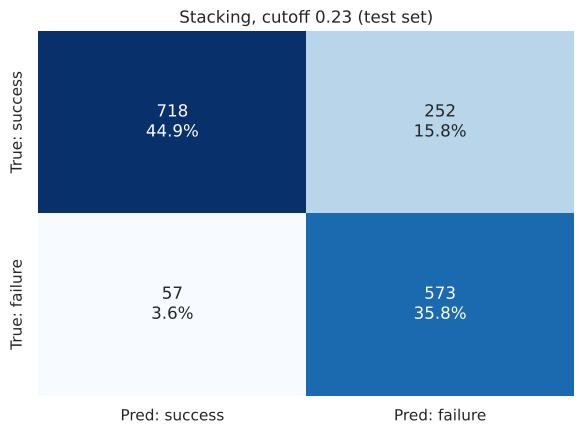

              precision    recall  f1-score   support

     success       0.93      0.74      0.82       970
     failure       0.69      0.91      0.79       630

    accuracy                           0.81      1600
   macro avg       0.81      0.82      0.81      1600
weighted avg       0.84      0.81      0.81      1600



In [21]:
from sklearn.model_selection import cross_val_predict

# Choose the cutoff from out-of-fold training predictions, so the test set is not used to pick it
oof = cross_val_predict(best, X_train, y_train, groups=g_train, cv=cv_inner, method='predict_proba', n_jobs=-1)[:, 1]
prec_t, rec_t, thr_t = precision_recall_curve(y_train, oof)
ok = np.where(rec_t[:-1] >= TARGET_RECALL)[0]
threshold = thr_t[ok[-1]] if len(ok) else 0.5
if not len(ok):
    log_decision('Threshold', 'keep the 0.5 cutoff', f'no cutoff reached {TARGET_RECALL:.0%} recall')

test_scores = get_scores(best, X_test)
rows = []
for label, t in [('Default (0.50)', 0.5), (f'Chosen ({threshold:.2f})', threshold)]:
    pred = (test_scores >= t).astype(int)
    rows.append({'Cutoff': label, 'Recall (failures caught)': recall_score(y_test, pred),
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Share of questions flagged': pred.mean(), 'F1': f1_score(y_test, pred)})
threshold_table = pd.DataFrame(rows)
display(threshold_table.round(3))

pred_chosen = (test_scores >= threshold).astype(int)
plot_confusion(y_test, pred_chosen, f'{best_name}, cutoff {threshold:.2f} (test set)')

## 14. Feature Importance
Permutation importance shuffles one predictor at a time and measures how much test ROC-AUC drops. It works for any model and treats each categorical variable as a whole. Logistic regression odds ratios show the direction of each numeric predictor's effect.

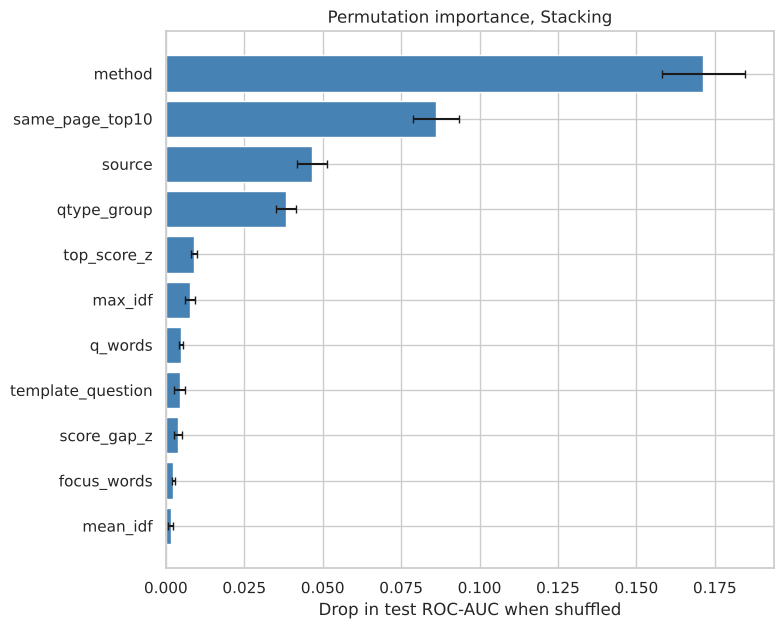

In [22]:
perm = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
err = pd.Series(perm.importances_std, index=FEATURES)[imp.index]

plt.figure(figsize=(8, 0.45 * len(FEATURES) + 1.5))
plt.barh(imp.index, imp.values, xerr=err.values, color='steelblue', capsize=3)
plt.title(f'Permutation importance, {best_name}')
plt.xlabel('Drop in test ROC-AUC when shuffled')
plt.tight_layout()
plt.show()

In [23]:
lr = models.get('Logistic Regression (Tuned)', models['Logistic Regression'])
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=lr.named_steps['prep'].get_feature_names_out())
odds = np.exp(coef[[f'num__{c}' for c in NUMERIC]]).rename(lambda s: s.replace('num__', ''))
odds.sort_values().round(2).to_frame('Odds ratio of failure (per 1 SD increase)')

,Odds ratio of failure (per 1 SD increase)
same_page_top10,0.42
template_question,0.72
score_gap_z,0.88
mean_idf,0.90
top_score_z,0.95
focus_words,0.97
q_words,1.09
max_idf,1.14


## 15. Interpretation of Findings
The findings are written by code from this run's results, so every number matches the tables and charts above, including when a different dataset is uploaded.

In [24]:
pct = lambda x: f'{x:.0%}'
def join_list(items):
    items = list(items)
    return items[0] if len(items) == 1 else ', '.join(items[:-1]) + ' and ' + items[-1]
def effect_label(v):
    return 'small' if v < 0.1 else 'moderate' if v < 0.3 else 'large'

rates = df.groupby('method')['failure'].mean().sort_values()
b = comparison.loc[0]
lines = []

# 1. Search methods
differ = cochran_p < ALPHA
s = (("**1. The search methods fail at very different rates.**" if differ else "**1. The search methods fail at similar rates.**")
     + " Failure rates were " + ', '.join(f'{m} {pct(r)}' for m, r in rates.items())
     + (f". Cochran's Q test shows the methods differ (p {fmt_p(cochran_p)})" if differ
        else f". Cochran's Q test finds no significant difference (p {fmt_p(cochran_p)})")
     + f", and {int(mc['Significant'].sum())} of {len(mc)} pairwise McNemar tests are significant after the Bonferroni correction.")
if differ and rates['Hybrid'] > rates['BM25'] and rates['LSA'] > rates['BM25']:
    s += (" LSA, an older semantic method, rarely finds the one exact passage among thousands. Because the hybrid combines "
          "BM25 with LSA, the weak LSA ranking pulled the hybrid below BM25 alone, so a hybrid only helps when both parts are good.")
lines.append(s)

# 2. Question type
if HAS_QTYPE:
    qt = df.groupby('qtype_group')['failure'].mean().sort_values()
    s = (f"**2. Question type is related to failure.** The chi-square test gives p {fmt_p(chi_p)} with a "
         f"{effect_label(cramers_v)} effect size (Cramér's V = {cramers_v:.2f}). "
         f"{join_list(qt.index[::-1][:3]).capitalize()} questions fail most often, while {join_list(qt.index[:2])} questions fail least.")
    if any(t in qt.index[::-1][:3] for t in ['research', 'outlook', 'inheritance']):
        s += (" These are questions about prognosis, genetics, and ongoing research, which matter a great deal to patients. "
              "Many NIH pages have similar sections on these topics, so the search often lands on the right kind of section for the wrong condition.")
    lines.append(s)

# 3. Best model
s = (f"**3. Failure is predictable.** {best_name} had the best cross-validated {metric_col} ({b[f'CV {metric_col}']:.3f} ± {b['CV SD']:.3f}). "
     f"On the held-out test set it reached a ROC-AUC of {b['Test ROC-AUC']:.3f} and a PR-AUC of {b['Test PR-AUC']:.3f}, "
     f"compared with {y_test.mean():.3f} for random guessing.")
lr_auc = comparison.set_index('Model').loc['Logistic Regression', 'Test ROC-AUC']
s += (f" Logistic regression reached {lr_auc:.3f}, so the ensemble models captured interactions a linear model misses."
      if b['Test ROC-AUC'] - lr_auc > 0.02 else f" Logistic regression reached {lr_auc:.3f}, nearly as good, so a simple model would also work.")
if b['Train ROC-AUC'] - b['Test ROC-AUC'] > 0.03:
    s += f" Train ROC-AUC was higher ({b['Train ROC-AUC']:.3f}), so the model overfits somewhat"
    s += (", but its cross-validated scores were stable across folds." if b['CV SD'] < 0.02
          else ", and its cross-validated scores varied across folds, so results on this dataset are less certain.")
lines.append(s)

# 4. More than the method
best_method = rates.idxmin()
w_auc = within_df.set_index('Method').loc[best_method, 'ROC-AUC within method']
s = (f"**4. The model learns more than which method was used.** A model that only knows the search method reaches a test "
     f"ROC-AUC of {method_only_auc:.3f}, versus {best_test_auc:.3f} for {best_name}.")
if not np.isnan(w_auc):
    s += f" Within {best_method}, the method that failed least, the model still ranks failures with a ROC-AUC of {w_auc:.3f}."
lines.append(s)

# 5. Threshold
t_row = threshold_table.iloc[1]
lines.append(f"**5. A cutoff of {threshold:.2f} catches {pct(t_row['Recall (failures caught)'])} of failed searches** on the test set "
             f"while flagging {pct(t_row['Share of questions flagged'])} of questions, with {pct(t_row['Precision'])} precision. "
             f"In practice, the flagged questions would go to a stronger search method or to a clinician instead of being answered automatically.")

# 6. Predictors
top3 = imp.sort_values(ascending=False).index[:3].tolist()
s = f"**6. The most important predictors were {join_list(['`' + t + '`' for t in top3])}.**"
if 'same_page_top10' in odds:
    s += (f" Each one standard deviation increase in `same_page_top10` multiplies the odds of failure by {odds['same_page_top10']:.2f}. "
          "When the top results cluster on one NIH page, the search usually found the right topic.")
s += f" For the score gap, the {gap_test} gave p {fmt_p(gap_p)} with {effect_name} = {gap_effect:.2f}"
s += (", a very small effect. With thousands of rows, tiny differences reach significance, so effect sizes matter more than p-values."
      if abs(gap_effect) < 0.1 else ".")
lines.append(s)

display(Markdown('\n\n'.join(lines)))

**1. The search methods fail at very different rates.** Failure rates were BM25 16%, TF-IDF 20%, Hybrid 50%, LSA 72%. Cochran's Q test shows the methods differ (p < 0.001), and 6 of 6 pairwise McNemar tests are significant after the Bonferroni correction. LSA, an older semantic method, rarely finds the one exact passage among thousands. Because the hybrid combines BM25 with LSA, the weak LSA ranking pulled the hybrid below BM25 alone, so a hybrid only helps when both parts are good.

**2. Question type is related to failure.** The chi-square test gives p < 0.001 with a moderate effect size (Cramér's V = 0.28). Research, inheritance and outlook questions fail most often, while information and causes questions fail least. These are questions about prognosis, genetics, and ongoing research, which matter a great deal to patients. Many NIH pages have similar sections on these topics, so the search often lands on the right kind of section for the wrong condition.

**3. Failure is predictable.** Stacking had the best cross-validated ROC-AUC (0.906 ± 0.005). On the held-out test set it reached a ROC-AUC of 0.915 and a PR-AUC of 0.855, compared with 0.394 for random guessing. Logistic regression reached 0.866, so the ensemble models captured interactions a linear model misses. Train ROC-AUC was higher (0.965), so the model overfits somewhat, but its cross-validated scores were stable across folds.

**4. The model learns more than which method was used.** A model that only knows the search method reaches a test ROC-AUC of 0.748, versus 0.915 for Stacking. Within BM25, the method that failed least, the model still ranks failures with a ROC-AUC of 0.937.

**5. A cutoff of 0.23 catches 91% of failed searches** on the test set while flagging 52% of questions, with 69% precision. In practice, the flagged questions would go to a stronger search method or to a clinician instead of being answered automatically.

**6. The most important predictors were `method`, `same_page_top10` and `source`.** Each one standard deviation increase in `same_page_top10` multiplies the odds of failure by 0.42. When the top results cluster on one NIH page, the search usually found the right topic. For the score gap, the Mann-Whitney U test gave p < 0.001 with rank-biserial r = 0.06, a very small effect. With thousands of rows, tiny differences reach significance, so effect sizes matter more than p-values.

### Health implications
A question-answering tool that always answers is riskiest exactly where patients care most, on questions about prognosis, inheritance, and new treatments. This analysis shows that likely retrieval failures can be flagged before an answer is written, using only information the system already has. A health system could use a model like this to route risky questions to a stronger search method, add a warning, or send them to a nurse or clinician.

### Limitations
- MedQuAD questions follow templates and are cleaner than real patient questions, so real-world failure rates are likely higher.
- The target depends on which search methods were run, so the results describe these four methods, not search in general.
- Modern neural search methods were not included because they need large model downloads. They are planned for my capstone.
- The test set is one fold of about 400 questions, so test metrics have some uncertainty. Cross-validated scores are reported alongside them for that reason.

## 16. Pipeline Design Summary

In [25]:
print('Adaptive decisions made in this run')
display(pd.DataFrame(decisions))

Adaptive decisions made in this run


,Step,Decision,Reason
0,Sampling,"search a random sample of 2,000 questions","13,675 questions are available"
1,Imbalance,use balanced class weights,the minority class is 39.3% of rows (threshold 45%)
2,Inference,use the Mann-Whitney U test for the score gap,Shapiro-Wilk normality p < 0.001


| Feature | What it does | Why it matters |
|---|---|---|
| **Central configuration** | Every setting, including the data source, primary metric, and target recall, is in Section 1 | The whole analysis can be changed or rerun by editing one cell |
| **User data upload** | A file picker accepts CSV, TSV, or Excel files. Column names are matched automatically and missing optional columns are filled in | Other users can analyze their own question and answer data with the same pipeline |
| **Automated profiling and validation** | Every column is profiled, settings and data are checked, and errors explain what to fix | Problems stop the pipeline early instead of producing wrong results |
| **Conditional logic** | Sample size, predictors, class weights, statistical tests, SVM, and tuning all adapt to the data and settings, and each choice is logged | The pipeline works on datasets with different sizes and columns |
| **Leakage-safe grouped splitting** | All rows for a question stay in the same fold, with an `assert` to check | Performance estimates are honest instead of inflated |
| **Predefined primary metric** | The best model is chosen by cross-validated `PRIMARY_METRIC`, not by the test set | The selection is fair and can be changed to fit a different goal |
| **Health-based decision threshold** | The cutoff is set to catch `TARGET_RECALL` of failures | Matches the higher cost of a missed failure in health settings |
| **Modular functions and error handling** | Loading, validation, searching, and evaluation are documented functions with `try/except` where steps can fail | Code is reusable, easier to read, and does not crash on a bad file |
| **Auto-generated findings** | The interpretation is written by code from the results | Written findings always match the current run |